In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

print("Classification libraries imported successfully!")

Classification libraries imported successfully!


In [2]:
clf_df = pd.read_csv("data/classification_escalation.csv")

print("Classification dataset loaded successfully!")

display(clf_df.head())

Classification dataset loaded successfully!


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


In [3]:
print("Dataset information:")
clf_df.info()

print("\nDataset shape:")
print(clf_df.shape)

print("\nMissing values:")
display(clf_df.isnull().sum())

print("\nStatistical summary:")
display(clf_df.describe(include="all"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ticket_id               900 non-null    str    
 1   complexity_score        878 non-null    float64
 2   team_experience_years   864 non-null    float64
 3   priority                887 non-null    str    
 4   channel                 891 non-null    str    
 5   customer_tenure_months  869 non-null    float64
 6   escalated               900 non-null    int64  
dtypes: float64(3), int64(1), str(3)
memory usage: 49.3 KB

Dataset shape:
(900, 7)

Missing values:


ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64


Statistical summary:


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
count,900,878.000000,864.000000,887,891,869.000000,900.000000
unique,900,NaN,NaN,4,4,NaN,NaN
top,T0000,NaN,NaN,Medium,Portal,NaN,NaN
freq,1,NaN,NaN,348,245,NaN,NaN
mean,NaN,5.523918,7.482639,NaN,NaN,40.018745,0.212222
std,NaN,2.869451,4.528235,NaN,NaN,26.126088,0.409109
min,NaN,1.000000,0.000000,NaN,NaN,1.065286,0.000000
25%,NaN,3.000000,4.000000,NaN,NaN,20.085430,0.000000
50%,NaN,5.000000,8.000000,NaN,NaN,34.649084,0.000000
75%,NaN,8.000000,11.000000,NaN,NaN,54.269475,0.000000


In [4]:
X_clf = clf_df.drop(columns=["ticket_id", "escalated"])
y_clf = clf_df["escalated"]

print("Features:")
display(X_clf.head())

print("Target distribution:")
display(y_clf.value_counts())

print("Target percentages:")
display(y_clf.value_counts(normalize=True) * 100)

Features:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months
0,2.0,15.0,Medium,Email,61.818896
1,9.0,6.0,Critical,Chat,110.024317
2,10.0,8.0,High,Phone,36.311244
3,2.0,1.0,Medium,Phone,85.127855
4,8.0,14.0,Medium,Chat,18.225059


Target distribution:


escalated
0    709
1    191
Name: count, dtype: int64

Target percentages:


escalated
0    78.777778
1    21.222222
Name: proportion, dtype: float64

In [5]:
numeric_features_clf = X_clf.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_clf = X_clf.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features_clf)
print("Categorical features:", categorical_features_clf)

Numerical features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical features: ['priority', 'channel']


The target variable is `escalated`, which indicates whether a support ticket was escalated.

We removed `ticket_id` because it is only an identifier and does not provide meaningful information for predicting escalation.

The remaining columns are used as input features.

In [6]:
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

print("Classification data split successfully!")

print("Training features:", X_train_clf.shape)
print("Testing features:", X_test_clf.shape)

Classification data split successfully!
Training features: (720, 5)
Testing features: (180, 5)


In [7]:
numeric_transformer_clf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_clf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_clf = ColumnTransformer([
    ("num", numeric_transformer_clf, numeric_features_clf),
    ("cat", categorical_transformer_clf, categorical_features_clf)
])

print("Classification preprocessing created successfully!")

Classification preprocessing created successfully!


We divided the dataset into 80% training data and 20% testing data.

We used stratified splitting to maintain approximately the same class distribution in both sets.

The split was performed before fitting any preprocessing steps. This prevents information from the testing data from influencing the training process.

In [8]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor_clf),
    ("classifier", LogisticRegression(max_iter=2000))
])

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor_clf),
    ("classifier", KNeighborsClassifier())
])

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor_clf),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

print("Classification models created successfully!")

Classification models created successfully!


In [9]:
clf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

classification_models = {
    "Logistic Regression": logistic_pipeline,
    "KNN": knn_pipeline,
    "Decision Tree": tree_pipeline
}

classification_results = []

for name, model in classification_models.items():

    scores = cross_validate(
        model,
        X_train_clf,
        y_train_clf,
        cv=clf_cv,
        scoring="f1",
        return_train_score=False
    )

    classification_results.append({
        "Model": name,
        "Mean F1": scores["test_score"].mean(),
        "Std F1": scores["test_score"].std()
    })

classification_results_df = pd.DataFrame(classification_results)

classification_results_df = classification_results_df.sort_values(
    by="Mean F1",
    ascending=False
)

display(classification_results_df)

,Model,Mean F1,Std F1
0,Logistic Regression,0.392651,0.062747
1,KNN,0.360835,0.050295
2,Decision Tree,0.330666,0.058126


In [10]:
clf_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

clf_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=clf_param_grid,
    scoring="f1",
    cv=clf_cv,
    n_jobs=-1
)

clf_grid_search.fit(X_train_clf, y_train_clf)

print("Best parameters:", clf_grid_search.best_params_)
print("Best cross-validation F1:", clf_grid_search.best_score_)

Best parameters: {'classifier__C': 10}
Best cross-validation F1: 0.4225932078257659


### Hyperparameter Tuning

We used GridSearchCV to tune Logistic Regression.

We tested different values of C, which controls the strength of regularization.

The best value was selected based on the highest cross-validation F1-score.

This helps improve model performance while reducing the risk of overfitting.

In [11]:
classification_comparison = classification_results_df.copy()

tuned_clf_result = pd.DataFrame([{
    "Model": "Tuned Logistic Regression",
    "Mean F1": clf_grid_search.best_score_,
    "Std F1": clf_grid_search.cv_results_["std_test_score"][
        clf_grid_search.best_index_
    ]
}])

classification_comparison = pd.concat(
    [classification_comparison, tuned_clf_result],
    ignore_index=True
)

classification_comparison = classification_comparison.sort_values(
    by="Mean F1",
    ascending=False
)

display(classification_comparison)

,Model,Mean F1,Std F1
3,Tuned Logistic Regression,0.422593,0.088225
0,Logistic Regression,0.392651,0.062747
1,KNN,0.360835,0.050295
2,Decision Tree,0.330666,0.058126


In [12]:
if clf_grid_search.best_score_ >= classification_results_df["Mean F1"].max():

    best_clf_model = clf_grid_search.best_estimator_
    best_clf_name = "Tuned Logistic Regression"

else:

    best_clf_name = classification_results_df.iloc[0]["Model"]
    best_clf_model = classification_models[best_clf_name]

print("Selected Classification Model:", best_clf_name)

best_clf_model.fit(X_train_clf, y_train_clf)

y_pred_clf = best_clf_model.predict(X_test_clf)

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_clf, zero_division=0))

final_f1 = f1_score(y_test_clf, y_pred_clf)

print("Final Classification Test F1-score:", final_f1)

Selected Classification Model: Tuned Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89       142
           1       0.62      0.21      0.31        38

    accuracy                           0.81       180
   macro avg       0.72      0.59      0.60       180
weighted avg       0.78      0.81      0.77       180

Final Classification Test F1-score: 0.3137254901960784


array([[137,   5],
       [ 30,   8]])

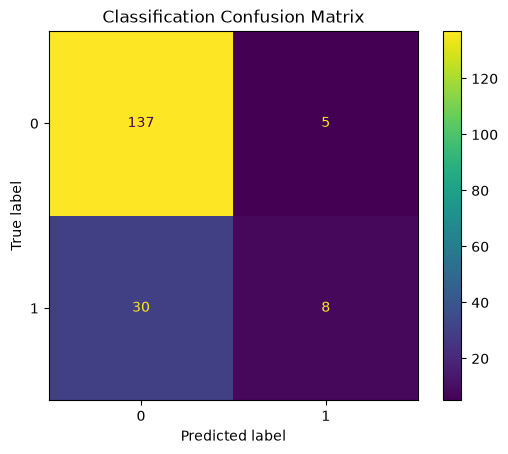

In [13]:
cm = confusion_matrix(y_test_clf, y_pred_clf)

display(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.title("Classification Confusion Matrix")
plt.show()

### Classification Results

The selected classification model was Tuned Logistic Regression.

Its test F1-score was 0.313725.

The classification report provides precision, recall, and F1-score for each class.

The confusion matrix helps us understand correct predictions, false positives, and false negatives.

The relatively low F1-score indicates that the model still has room for improvement.

## Experiment B: Regression

This experiment predicts the resolution time of customer support tickets.

The target variable is `resolution_time_hours`.

In [14]:
from sklearn.model_selection import KFold

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Regression libraries imported successfully!")

Regression libraries imported successfully!


In [15]:
reg_df = pd.read_csv("data/resolution_time_regression.csv")

print("Regression dataset loaded successfully!")

display(reg_df.head())

Regression dataset loaded successfully!


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


In [16]:
print("Dataset information:")
reg_df.info()

print("\nDataset shape:")
print(reg_df.shape)

print("\nMissing values:")
display(reg_df.isnull().sum())

print("\nStatistical summary:")
display(reg_df.describe(include="all"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ticket_id               800 non-null    str    
 1   complexity_score        784 non-null    float64
 2   team_experience_years   776 non-null    float64
 3   priority                800 non-null    str    
 4   channel                 800 non-null    str    
 5   customer_tenure_months  780 non-null    float64
 6   resolution_time_hours   800 non-null    float64
dtypes: float64(4), str(3)
memory usage: 43.9 KB

Dataset shape:
(800, 7)

Missing values:


ticket_id                  0
complexity_score          16
team_experience_years     24
priority                   0
channel                    0
customer_tenure_months    20
resolution_time_hours      0
dtype: int64


Statistical summary:


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
count,800,784.000000,776.000000,800,800,780.000000,800.000000
unique,800,NaN,NaN,4,4,NaN,NaN
top,R0000,NaN,NaN,Medium,Phone,NaN,NaN
freq,1,NaN,NaN,311,206,NaN,NaN
mean,NaN,5.545918,7.496134,NaN,NaN,39.577416,5.873160
std,NaN,2.849200,4.479342,NaN,NaN,26.510500,4.144974
min,NaN,1.000000,0.000000,NaN,NaN,0.884553,0.500000
25%,NaN,3.000000,4.000000,NaN,NaN,19.697823,2.631319
50%,NaN,6.000000,8.000000,NaN,NaN,33.979577,5.387386
75%,NaN,8.000000,11.000000,NaN,NaN,54.299824,8.345903


In [17]:
X_reg = reg_df.drop(columns=["ticket_id", "resolution_time_hours"])
y_reg = reg_df["resolution_time_hours"]

print("Features:")
display(X_reg.head())

print("Target summary:")
display(y_reg.describe())

Features:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months
0,7.0,10.0,Medium,Chat,32.638377
1,4.0,15.0,Medium,Chat,45.273760
2,4.0,13.0,Low,Portal,44.878323
3,1.0,10.0,High,Phone,40.095034
4,3.0,15.0,Low,Portal,47.451134


Target summary:


count    800.000000
mean       5.873160
std        4.144974
min        0.500000
25%        2.631319
50%        5.387386
75%        8.345903
max       27.488229
Name: resolution_time_hours, dtype: float64

In [18]:
numeric_features_reg = X_reg.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_reg = X_reg.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features_reg)
print("Categorical features:", categorical_features_reg)

Numerical features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical features: ['priority', 'channel']


In [19]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Regression data split successfully!")

print("Training features:", X_train_reg.shape)
print("Testing features:", X_test_reg.shape)

Regression data split successfully!
Training features: (640, 5)
Testing features: (160, 5)


In [20]:
numeric_transformer_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_reg = ColumnTransformer([
    ("num", numeric_transformer_reg, numeric_features_reg),
    ("cat", categorical_transformer_reg, categorical_features_reg)
])

print("Regression preprocessing created successfully!")

Regression preprocessing created successfully!


In [21]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", LinearRegression())
])

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", Ridge())
])

reg_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

print("All regression pipelines created successfully!")

All regression pipelines created successfully!


In [22]:
reg_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

regression_models = {
    "Linear Regression": linear_pipeline,
    "Ridge Regression": ridge_pipeline,
    "Decision Tree": reg_tree_pipeline
}

regression_results = []

for name, model in regression_models.items():

    scores = cross_validate(
        model,
        X_train_reg,
        y_train_reg,
        cv=reg_cv,
        scoring="neg_mean_absolute_error",
        return_train_score=False
    )

    mae_scores = -scores["test_score"]

    regression_results.append({
        "Model": name,
        "Mean MAE": mae_scores.mean(),
        "Std MAE": mae_scores.std()
    })

regression_results_df = pd.DataFrame(regression_results)

regression_results_df = regression_results_df.sort_values(
    by="Mean MAE",
    ascending=True
)

display(regression_results_df)

,Model,Mean MAE,Std MAE
1,Ridge Regression,2.035127,0.171404
0,Linear Regression,2.035134,0.171650
2,Decision Tree,3.239097,0.053807


In [23]:
ridge_param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_mean_absolute_error",
    cv=reg_cv,
    n_jobs=-1
)

ridge_grid_search.fit(X_train_reg, y_train_reg)

print("Best Ridge Parameters:")

print(ridge_grid_search.best_params_)

print("\nBest Cross-Validation MAE:")

print(-ridge_grid_search.best_score_)

Best Ridge Parameters:
{'regressor__alpha': 0.1}

Best Cross-Validation MAE:
2.035118085555478


In [24]:
regression_comparison = regression_results_df.copy()

tuned_ridge_result = pd.DataFrame([{
    "Model": "Tuned Ridge Regression",
    "Mean MAE": -ridge_grid_search.best_score_,
    "Std MAE": ridge_grid_search.cv_results_["std_test_score"][
        ridge_grid_search.best_index_
    ]
}])

regression_comparison = pd.concat(
    [regression_comparison, tuned_ridge_result],
    ignore_index=True
)

regression_comparison = regression_comparison.sort_values(
    by="Mean MAE",
    ascending=True
)

display(regression_comparison)

,Model,Mean MAE,Std MAE
3,Tuned Ridge Regression,2.035118,0.171627
0,Ridge Regression,2.035127,0.171404
1,Linear Regression,2.035134,0.171650
2,Decision Tree,3.239097,0.053807


### Regression Model Validation

We compared Linear Regression, Ridge Regression, and Decision Tree Regression using five-fold cross-validation.

We used Mean Absolute Error (MAE) as the primary evaluation metric.

A lower MAE indicates that the model makes predictions closer to the actual resolution times.

In [25]:
if -ridge_grid_search.best_score_ <= regression_results_df["Mean MAE"].min():

    best_reg_model = ridge_grid_search.best_estimator_
    best_reg_name = "Tuned Ridge Regression"

else:

    best_reg_name = regression_results_df.iloc[0]["Model"]
    best_reg_model = regression_models[best_reg_name]

print("Selected Regression Model:", best_reg_name)

best_reg_model.fit(X_train_reg, y_train_reg)

y_pred_reg = best_reg_model.predict(X_test_reg)

Selected Regression Model: Tuned Ridge Regression


In [26]:
test_mae = mean_absolute_error(y_test_reg, y_pred_reg)

test_rmse = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_reg)
)

print("Final Regression Test MAE:", test_mae)
print("Final Regression Test RMSE:", test_rmse)

Final Regression Test MAE: 2.2300861441806563
Final Regression Test RMSE: 3.4027561084563143


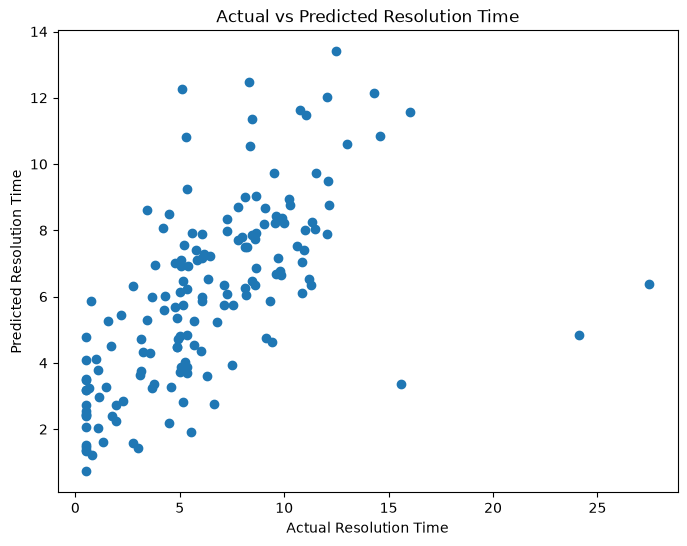

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_reg, y_pred_reg)

plt.xlabel("Actual Resolution Time")
plt.ylabel("Predicted Resolution Time")
plt.title("Actual vs Predicted Resolution Time")

plt.show()

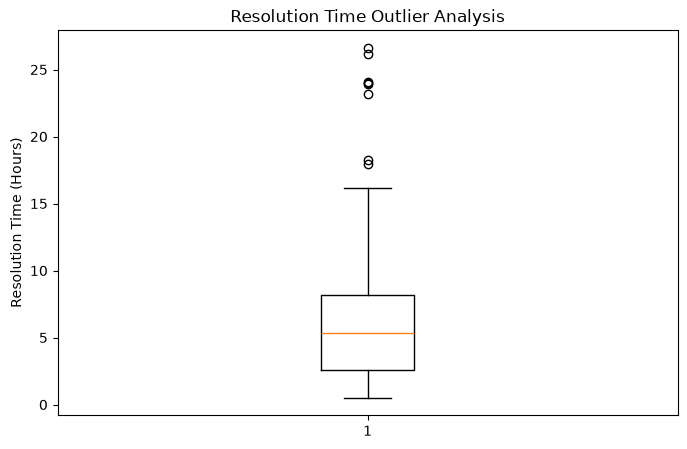

In [28]:
plt.figure(figsize=(8, 5))

plt.boxplot(y_train_reg)

plt.title("Resolution Time Outlier Analysis")
plt.ylabel("Resolution Time (Hours)")

plt.show()

In [29]:
Q1 = y_train_reg.quantile(0.25)
Q3 = y_train_reg.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = y_train_reg[
    (y_train_reg < lower_bound) |
    (y_train_reg > upper_bound)
]

print("Number of potential outliers:", len(outliers))
display(outliers)

Number of potential outliers: 8


193    26.615113
51     23.929861
188    26.135421
19     17.981195
298    23.183383
113    18.267015
573    24.017656
502    24.100668
Name: resolution_time_hours, dtype: float64

# Reflection Questions

1. Why is stratification important when splitting the classification dataset?

Stratification helps maintain approximately the same proportion of each class in both the training and testing sets. This is important because it prevents one class from being underrepresented in either set and makes the evaluation more reliable.

2. Why should preprocessing be included inside a pipeline?

Preprocessing should be included inside a pipeline to prevent data leakage. The pipeline ensures that imputation, scaling, and encoding are fitted only on the training data during each cross-validation fold. This helps produce a more reliable evaluation.

3. What does variability across cross-validation folds tell us?

Variability shows how consistently a model performs across different subsets of the data. A smaller standard deviation means the model performs more consistently, while a larger standard deviation suggests that its performance changes depending on the data used.

4. Why should the test set be used only once?

The test set should be used only once for the final evaluation because it provides an independent estimate of how well the selected model performs on unseen data. Repeatedly checking the test set and making changes based on its results can lead to overfitting.

5. What deployment constraints might affect the choice of a model?

Deployment decisions may depend on prediction speed, memory usage, computational resources, interpretability, and maintenance. A model with slightly better accuracy may not always be the best choice if it requires too many resources or is difficult to maintain.


## Final Model Justification

Tuned Logistic Regression was selected for classification based on its cross-validation F1-score.

Tuned Ridge Regression was selected for regression based on its cross-validation MAE.

The two experiments used different evaluation metrics because they solve different prediction problems.

## Limitations

The classification model achieved a relatively low test F1-score, indicating that its ability to identify escalated tickets could be improved.

The regression model's predictions also contain errors, as shown by its MAE and RMSE.

Future improvements could include testing additional models, exploring more hyperparameters, and investigating the influence of individual features.